# Department for Transport: Food Stores

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_excel("dft_LSOA_foodstores.xlsx", sheet_name='2019')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (32844, 41)


,LSOA_code,Region,LA_Code,LA_Name,Food_pop,FoodPTt,FoodPT15n,FoodPT30n,FoodPT45n,FoodPT60n,...,FoodCar60pct,FoodWalkt,FoodWalk15n,FoodWalk30n,FoodWalk45n,FoodWalk60n,FoodWalk15pct,FoodWalk30pct,FoodWalk45pct,FoodWalk60pct
0,E01000001,London,E09000001,City of London,863.214592,6.205913,10.0,10.0,10.0,10.0,...,100.0,3.256450,10.000000,10.0,10.0,10.0,100.0,100.0,100.0,100.0
1,E01000002,London,E09000001,City of London,817.885979,6.233856,10.0,10.0,10.0,10.0,...,100.0,4.272084,10.000000,10.0,10.0,10.0,100.0,100.0,100.0,100.0
2,E01000003,London,E09000001,City of London,805.075699,6.157319,10.0,10.0,10.0,10.0,...,100.0,3.504504,10.000000,10.0,10.0,10.0,100.0,100.0,100.0,100.0
3,E01000005,London,E09000001,City of London,460.184021,5.652976,10.0,10.0,10.0,10.0,...,100.0,1.876767,10.000000,10.0,10.0,10.0,100.0,100.0,100.0,100.0
4,E01000006,London,E09000002,Barking and Dagenham,601.834534,6.728950,10.0,10.0,10.0,10.0,...,100.0,6.800553,9.222836,10.0,10.0,10.0,100.0,100.0,100.0,100.0


# Data Cleaning

In [4]:
#removes all leading and trailing whitespace from the column names
df.columns = df.columns.str.strip()

In [5]:
#check for missing values, duplicate rows/columns, and only display the unique rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique LSOAs:", df["LSOA_code"].nunique())

Missing values: 0
Duplicates: 0
Unique LSOAs: 32844


# Exploratory Data Analysis  
In the case of Journey to Food Stores, did not keep all the 15/30/45/60-minute count and percentage variables, because that adds a lot of highly correlated features without giving ML models much extra information.

In [36]:
#filtering out the relevant columns
food = df[
    [
        "LSOA_code",
        "Region",
        "LA_Code",
        "LA_Name",
        "Food_pop",
        "FoodPTt",
        "FoodPT30pct", #% users within 30 minutes of food stores by Public transport
        "FoodWalkt",
        "FoodCart"
    ] ].copy()

food.head()

,LSOA_code,Region,LA_Code,LA_Name,Food_pop,FoodPTt,FoodPT30pct,FoodWalkt,FoodCart
0,E01000001,London,E09000001,City of London,863.214592,6.205913,100.0,3.256450,6.205913
1,E01000002,London,E09000001,City of London,817.885979,6.233856,100.0,4.272084,6.233856
2,E01000003,London,E09000001,City of London,805.075699,6.157319,100.0,3.504504,6.157319
3,E01000005,London,E09000001,City of London,460.184021,5.652976,100.0,1.876767,5.652976
4,E01000006,London,E09000002,Barking and Dagenham,601.834534,6.728950,100.0,6.800553,6.728950


In [37]:
food.info()
# Missing values
print(food.isnull().sum())

# Duplicate LSOAs
print("Duplicate LSOAs:",
      food["LSOA_code"].duplicated().sum())

# Remove duplicates if any
food = food.drop_duplicates(subset="LSOA_code")

# Check numerical statistics
food.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32844 entries, 0 to 32843
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   LSOA_code    32844 non-null  object 
 1   Region       32844 non-null  object 
 2   LA_Code      32844 non-null  object 
 3   LA_Name      32844 non-null  object 
 4   Food_pop     32844 non-null  float64
 5   FoodPTt      32844 non-null  float64
 6   FoodPT30pct  32844 non-null  float64
 7   FoodWalkt    32844 non-null  float64
 8   FoodCart     32844 non-null  float64
dtypes: float64(5), object(4)
memory usage: 2.3+ MB
LSOA_code      0
Region         0
LA_Code        0
LA_Name        0
Food_pop       0
FoodPTt        0
FoodPT30pct    0
FoodWalkt      0
FoodCart       0
dtype: int64
Duplicate LSOAs: 0


,Food_pop,FoodPTt,FoodPT30pct,FoodWalkt,FoodCart
count,32844.000000,32844.000000,32844.000000,32844.000000,32844.000000
mean,712.006363,7.112382,99.991509,10.862377,7.112382
std,142.226618,1.578366,0.421274,12.782040,1.578366
min,288.524719,5.396886,66.421570,0.891505,5.396886
25%,623.263338,6.276416,100.000000,5.078032,6.276416
50%,686.058746,6.691679,100.000000,7.143061,6.691679
75%,782.025129,7.323224,100.000000,10.614465,7.323224
max,1542.486511,31.493863,100.000000,120.000000,31.493863


In [38]:
# Correlation: To find whether several food accessibility measures are strongly related
accessibility_cols = [
    "FoodPTt",
    "FoodPT30pct",
    "FoodWalkt"
]
food[accessibility_cols].corr().round(2)

,FoodPTt,FoodPT30pct,FoodWalkt
FoodPTt,1.00,-0.21,0.96
FoodPT30pct,-0.21,1.00,-0.14
FoodWalkt,0.96,-0.14,1.00


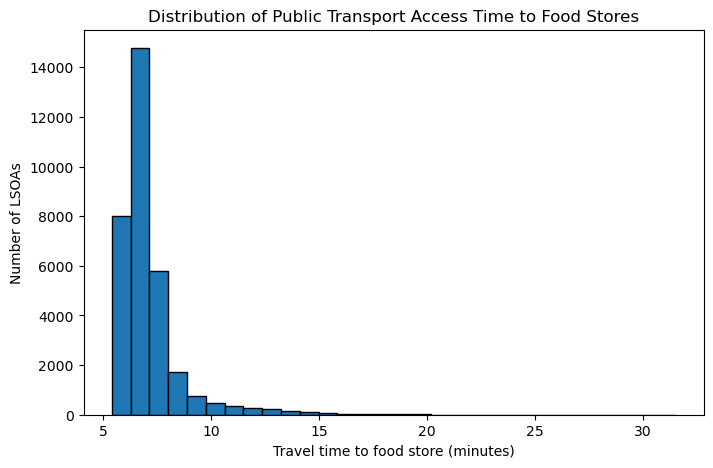

In [39]:
plt.figure(figsize=(8, 5))

plt.hist(
    food["FoodPTt"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Travel time to food store (minutes)")
plt.ylabel("Number of LSOAs")
plt.title("Distribution of Public Transport Access Time to Food Stores")

plt.show()

The above graph shows strong Right-Skewed Distribution: The travel times are heavily concentrated at the lower end, peaking sharply between 6 and 7 minutes for nearly 15,000 LSOAs (regions) across England. High Food Store Accessibility: The vast majority of areas have public transport travel times under 8 minutes to reach a food store, indicating generally quick access across most neighborhoods.

Rapid Drop-Off: The count drops significantly beyond 8 minutes, with very few areas taking longer than 15 minutes and almost none exceeding 20 minutes.

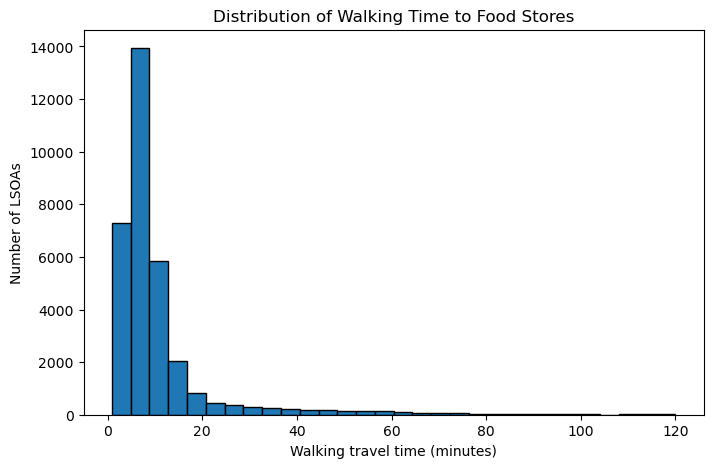

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(
    food["FoodWalkt"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Walking travel time (minutes)")
plt.ylabel("Number of LSOAs")
plt.title("Distribution of Walking Time to Food Stores")

plt.show()

Heavily Right-Skewed Distribution: The vast majority of LSOAs are clustered at the lower end, showing a sharp peak around 5 to 10 minutes of walking time to the nearest food store. High Walkable Accessibility: Most areas have reasonable pedestrian access to food stores, with counts dropping off rapidly beyond 15 minutes.

Long Tail / Outliers: A thin tail extends all the way to 120 minutes, highlighting a small number of rural or isolated neighborhoods with very poor walking accessibility to grocery services.

In [ ]:
# Regional comparison for the time it takes to access foodstores by Public Transport and by Walking
region_food = (
    food.groupby("Region")[
        ["FoodPTt", "FoodWalkt"]
    ]
    .mean()
    .sort_values("FoodPTt")
)

region_food.round(2)

,FoodPTt,FoodWalkt
Region,,
London,6.65,6.35
North West,6.91,9.48
North East,6.94,9.51
Yorkshire and The Humber,7.12,11.41
West Midlands,7.16,11.30
South East,7.22,11.43
East Midlands,7.29,12.60
East,7.42,13.30
South West,7.44,13.98


In [41]:
#Food accessibility travel time
food["food_access_time"] = food["FoodPTt"]
#Poor food accessibility indicator
food["poor_food_access"] = (food["FoodPTt"] > food["FoodPTt"].median()).astype(int)

Food Accessibility Travel Time:                                                                                                                          Higher values indicate poorer accessibility to food stores by public transport/walking.                          
Poor Accessibility indicator is a feature that shows                                                                                                    
0 = better-than-median food store accessibility
1 = worse-than-median food store accessibility

In [42]:
food["food_access_zscore"] = (
    food["FoodPTt"] -
    food["FoodPTt"].mean()
) / food["FoodPTt"].std()

In [43]:
# Public transport to car accessibility gap
food["Food_PT_Car_Gap"] = food["FoodPTt"] - food["FoodCart"]

# Inspect the new feature
food["Food_PT_Car_Gap"].describe()

count    32844.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: Food_PT_Car_Gap, dtype: float64

In [ ]:
food_features = food[
    [
        "LSOA_code",
        "FoodPTt",     #Travel time in minutes to nearest food store by Public Transport in munites
        "FoodPT30pct", #% users within 30 minutes of food stores by Public Transport in minutes
        "FoodWalkt",   #Travel time in minutes to nearest food store by walking in minutes
        "FoodCart",    #Travel time in minutes to nearest food store by Car in minutes
        "Food_PT_Car_Gap" #Time difference to access food stores using Public transport and Car
    ]
].copy()

food_features.head()

,LSOA_code,FoodPTt,FoodPT30pct,FoodWalkt,FoodCart,Food_PT_Car_Gap
0,E01000001,6.205913,100.0,3.256450,6.205913,0.0
1,E01000002,6.233856,100.0,4.272084,6.233856,0.0
2,E01000003,6.157319,100.0,3.504504,6.157319,0.0
3,E01000005,5.652976,100.0,1.876767,5.652976,0.0
4,E01000006,6.728950,100.0,6.800553,6.728950,0.0


The dataset was cleaned and transformed and then the selected features were then saved into a new dataset as shown below

In [45]:
food_features.to_excel(
    "food_store_features.xlsx",
    index=False
)